# Module 04 — Differential Calculus for ML

This notebook is the runnable companion to the concept guide. It builds every object of the
module in plain NumPy — finite differences, activation derivatives, gradients, Jacobians,
Hessians, Taylor models, the matrix-calculus identities and the gradients of ML losses — and
checks each analytic formula against a numerical one.

Read the [concept guide](README.md) first, or keep it open alongside: each section below
mirrors a numbered section there. Run the cells top to bottom; the "Try it yourself"
prompts are invitations to break things and see what happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=5, suppress=True)

## 1. The derivative and its numerical approximation

The derivative is the limit of a difference quotient,

$$f'(x) = \lim_{h\to 0}\frac{f(x+h)-f(x)}{h},$$

and a computer approximates it with a *finite* $h$. Two schemes:

| scheme | formula | truncation error |
|---|---|---|
| forward | $\dfrac{f(x+h)-f(x)}{h}$ | $O(h)$ |
| central | $\dfrac{f(x+h)-f(x-h)}{2h}$ | $O(h^2)$ |

Truncation error shrinks with $h$, but *round-off* error grows like $\varepsilon|f|/h$
(with machine epsilon $\varepsilon \approx 2.2\times 10^{-16}$), because two nearly equal
numbers are subtracted and the difference is divided by something tiny. Let us see both effects.

forward, h=0.1 : 12.61000000000001    error 0.6100000000000101
central, h=0.1 : 12.010000000000009    error 0.010000000000008669


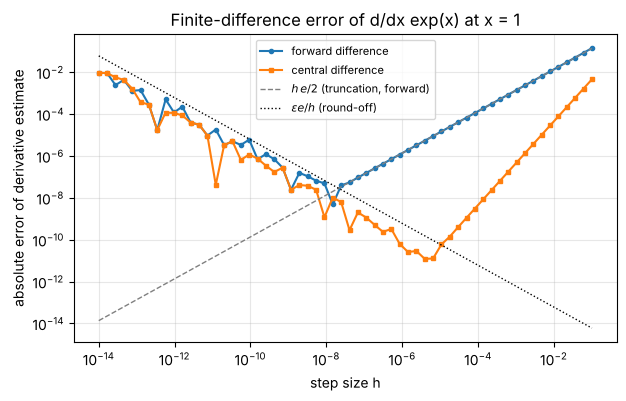

best forward : h = 1.5e-08, error 4.8e-09
best central : h = 3.9e-06, error 1.2e-11


In [2]:
def fwd_diff(f, x, h):
    return (f(x + h) - f(x)) / h

def central_diff(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

# Hand example from the guide: f(x) = x^3 at x = 2, exact derivative 12
f = lambda x: x**3
print("forward, h=0.1 :", fwd_diff(f, 2.0, 0.1), "   error", fwd_diff(f, 2.0, 0.1) - 12)
print("central, h=0.1 :", central_diff(f, 2.0, 0.1), "   error", central_diff(f, 2.0, 0.1) - 12)

# Now sweep h over 14 decades for f(x) = exp(x) at x = 1 (exact derivative e)
g, x0, exact = np.exp, 1.0, np.e
hs = np.logspace(-14, -1, 60)
err_f = np.abs(fwd_diff(g, x0, hs) - exact)
err_c = np.abs(central_diff(g, x0, hs) - exact)

plt.loglog(hs, err_f, "o-", ms=3, label="forward difference")
plt.loglog(hs, err_c, "s-", ms=3, label="central difference")
plt.loglog(hs, hs * np.e / 2, "--", lw=1, color="gray", label=r"$h\,e/2$ (truncation, forward)")
plt.loglog(hs, 2.2e-16 * np.e / hs, ":", lw=1, color="black", label=r"$\varepsilon e / h$ (round-off)")
plt.xlabel("step size h"); plt.ylabel("absolute error of derivative estimate")
plt.title("Finite-difference error of d/dx exp(x) at x = 1")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

i_f, i_c = np.argmin(err_f), np.argmin(err_c)
print(f"best forward : h = {hs[i_f]:.1e}, error {err_f[i_f]:.1e}")
print(f"best central : h = {hs[i_c]:.1e}, error {err_c[i_c]:.1e}")

Notice the V shape. On the right, both curves are straight lines: slope 1 for the forward
scheme (error $\propto h$) and slope 2 for the central scheme (error $\propto h^2$), exactly
the truncation orders. On the left, both ride the dotted round-off line $\varepsilon e/h$, which
*rises* as $h$ shrinks. The best step is where the two meet: about $10^{-8}$ for forward
(error $\sim 10^{-8}$) and about $10^{-5}$ to $10^{-6}$ for central (error $\sim 10^{-10}$).
Below $h \approx 10^{-12}$ the estimate is mostly noise — "smaller is safer" is false.

For the hand example, the forward error $0.61$ matches $\tfrac{h}{2}f''(2) = 0.05\cdot 12 = 0.6$,
and the central error $0.01$ matches $\tfrac{h^2}{6}f'''(2) = \tfrac{0.01}{6}\cdot 6 = 0.01$.

**Try it yourself:** replace `np.exp` by `np.sin` (exact derivative `np.cos(1.0)`), or cast
inputs to `np.float32` — where does the V's bottom move, and why?

## 2. The rules you actually use — activation functions and their derivatives

The chain rule says that composed functions multiply their slopes. Applied to the sigmoid
$\sigma(z) = 1/(1+e^{-z})$ it gives $\sigma'(z) = \sigma(z)(1-\sigma(z))$; for
$\tanh$ it gives $1 - \tanh^2 z$; $\mathrm{softplus}(z) = \ln(1+e^z)$ has derivative
$\sigma(z)$; and $\mathrm{ReLU}(z) = \max(0,z)$ has derivative $\mathbb{1}[z>0]$ (with any
value in $[0,1]$ acceptable as a subgradient at $z = 0$).

Below we implement each derivative *from the formula* and confirm it against a central
difference — the habit this module wants you to form.

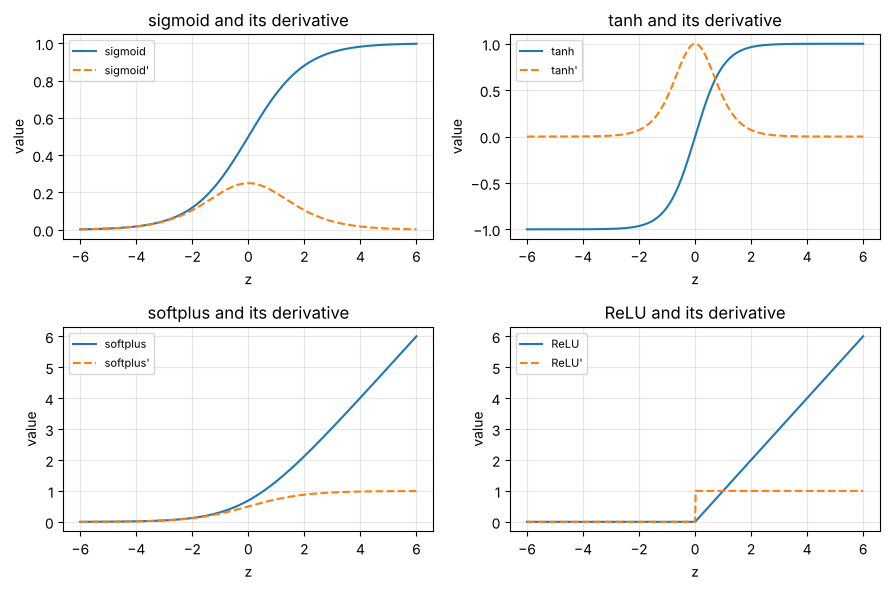

sigmoid   max |analytic - numerical| = 6.92e-11
tanh      max |analytic - numerical| = 4.57e-11
softplus  max |analytic - numerical| = 2.39e-10
ReLU      max |analytic - numerical| = 1.40e-10

max of sigma'(z) = 0.25   (at z = 0: exactly 1/4)
sigma'(2) = 0.10499358540350662   sigma'(5) = 0.006648056670790033


In [3]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

activations = {
    "sigmoid":  (sigmoid,                         lambda z: sigmoid(z) * (1 - sigmoid(z))),
    "tanh":     (np.tanh,                         lambda z: 1 - np.tanh(z)**2),
    "softplus": (lambda z: np.logaddexp(0.0, z),  sigmoid),
    "ReLU":     (lambda z: np.maximum(0.0, z),    lambda z: (z > 0).astype(float)),
}

z = np.linspace(-6, 6, 601)
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, (name, (act, dact)) in zip(axes.ravel(), activations.items()):
    ax.plot(z, act(z), label=name)
    ax.plot(z, dact(z), "--", label=name + "'")
    ax.set_title(name + " and its derivative"); ax.set_xlabel("z"); ax.set_ylabel("value")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

# analytic vs numerical derivative, away from the ReLU kink
zz = np.linspace(-4, 4, 17) + 0.013
for name, (act, dact) in activations.items():
    num = central_diff(act, zz, 1e-6)
    print(f"{name:9s} max |analytic - numerical| = {np.max(np.abs(dact(zz) - num)):.2e}")

print("\nmax of sigma'(z) =", np.max(activations['sigmoid'][1](z)), "  (at z = 0: exactly 1/4)")
print("sigma'(2) =", activations['sigmoid'][1](2.0), "  sigma'(5) =", activations['sigmoid'][1](5.0))

Every analytic derivative agrees with the numerical one to about $10^{-10}$. Two things to
notice in the plots: the sigmoid's derivative never exceeds $1/4$ and is already $0.105$ at
$z = 2$ — this *saturation* is the origin of vanishing gradients; and ReLU's derivative is
exactly $1$ wherever the unit is active, so gradients pass through unchanged.

A one-neuron network makes the chain rule concrete: $z = wx + b$, $p = \sigma(z)$,
$L = (p - y)^2$. Then $\dfrac{dL}{dw} = \dfrac{dL}{dp}\dfrac{dp}{dz}\dfrac{dz}{dw} = 2(p-y)\cdot p(1-p)\cdot x$.

In [4]:
w, b, x, y = 0.5, 0.0, 2.0, 1.0
z = w * x + b
p = sigmoid(z)
L = (p - y)**2
dL_dw = 2 * (p - y) * p * (1 - p) * x
print(f"forward : z = {z}, p = {p:.4f}, L = {L:.4f}")
print(f"backward: dL/dw = 2(p-y) * p(1-p) * x = {dL_dw:.4f}")
print("numerical check:", central_diff(lambda w_: (sigmoid(w_ * x + b) - y)**2, w, 1e-6))

# why sigmoid networks vanish: ten layers, each contributing at most 1/4
print("\nten sigmoid layers, best case gradient factor:", 0.25**10)

forward : z = 1.0, p = 0.7311, L = 0.0723
backward: dL/dw = 2(p-y) * p(1-p) * x = -0.2115
numerical check: -0.21150837112987597

ten sigmoid layers, best case gradient factor: 9.5367431640625e-07


## 3. Partial derivatives and the gradient

For $f:\mathbb{R}^n\to\mathbb{R}$, the gradient $\nabla f$ collects the partial derivatives.
The directional derivative along a unit vector $\mathbf{u}$ is $D_{\mathbf{u}} f = \nabla f^\top \mathbf{u}$,
and by Cauchy–Schwarz it is largest when $\mathbf{u}$ points along $\nabla f$ — the gradient is
the **direction of steepest ascent**, with slope $\lVert\nabla f\rVert$, and it is **perpendicular
to level sets**.

We use the guide's example $f(x,y) = x^2 + 3xy$ with $\nabla f = (2x + 3y,\; 3x)$.

analytic gradient at (1,2): [8. 3.]   numerical: [8. 3.]
norm of gradient: 8.54400374531753


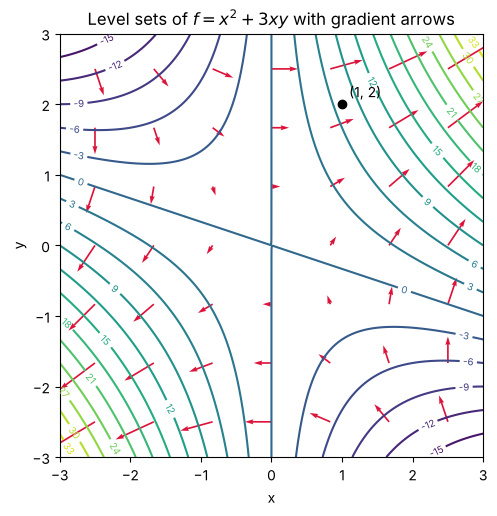

In [5]:
def f2(v):
    x, y = v
    return x**2 + 3 * x * y

def grad_f2(v):
    x, y = v
    return np.array([2 * x + 3 * y, 3 * x])

def grad_fd(f, x, h=1e-6):
    # central-difference gradient for any f: R^n -> R  (built from scratch; reused below)
    x = np.asarray(x, dtype=float)
    g = np.zeros_like(x)
    for i in range(x.size):
        e = np.zeros_like(x); e[i] = h
        g[i] = (f(x + e) - f(x - e)) / (2 * h)
    return g

p0 = np.array([1.0, 2.0])
print("analytic gradient at (1,2):", grad_f2(p0), "  numerical:", grad_fd(f2, p0))
print("norm of gradient:", np.linalg.norm(grad_f2(p0)))

# contour plot with gradient arrows
xs = np.linspace(-3, 3, 200); ys = np.linspace(-3, 3, 200)
X, Y = np.meshgrid(xs, ys)
Z = X**2 + 3 * X * Y
plt.figure(figsize=(6.5, 5.5))
cs = plt.contour(X, Y, Z, levels=20, cmap="viridis")
plt.clabel(cs, inline=True, fontsize=7, fmt="%.0f")
qx, qy = np.meshgrid(np.linspace(-2.5, 2.5, 7), np.linspace(-2.5, 2.5, 7))
gx, gy = 2 * qx + 3 * qy, 3 * qx
plt.quiver(qx, qy, gx, gy, color="crimson", angles="xy", scale=120, width=0.004)
plt.plot(*p0, "ko"); plt.annotate("(1, 2)", p0 + 0.1)
plt.gca().set_aspect("equal")
plt.xlabel("x"); plt.ylabel("y"); plt.title(r"Level sets of $f = x^2 + 3xy$ with gradient arrows")
plt.show()

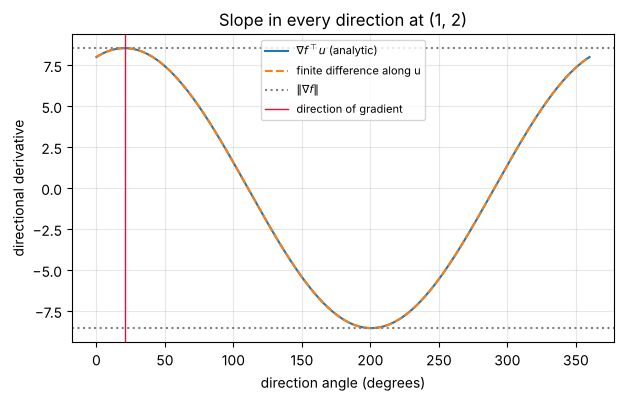

steepest ascent at 20.6 deg; gradient points at 20.6 deg
max slope 8.5440 vs ||grad|| = 8.5440
slope perpendicular to gradient: 0.0


In [6]:
# the directional derivative as a function of direction, at (1, 2)
angles = np.linspace(0, 2 * np.pi, 3601)
U = np.stack([np.cos(angles), np.sin(angles)])           # unit vectors
g = grad_f2(p0)
dir_deriv = g @ U                                        # grad^T u for every direction
numeric = np.array([(f2(p0 + 1e-6 * u) - f2(p0 - 1e-6 * u)) / 2e-6 for u in U.T])

best = angles[np.argmax(dir_deriv)]
grad_angle = np.arctan2(g[1], g[0])
plt.plot(np.degrees(angles), dir_deriv, label=r"$\nabla f^\top u$ (analytic)")
plt.plot(np.degrees(angles), numeric, "--", label="finite difference along u")
plt.axhline(np.linalg.norm(g), color="gray", ls=":", label=r"$\|\nabla f\|$")
plt.axhline(-np.linalg.norm(g), color="gray", ls=":")
plt.axvline(np.degrees(grad_angle), color="crimson", lw=1, label="direction of gradient")
plt.xlabel("direction angle (degrees)"); plt.ylabel("directional derivative")
plt.title("Slope in every direction at (1, 2)"); plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

print(f"steepest ascent at {np.degrees(best):.1f} deg; gradient points at {np.degrees(grad_angle):.1f} deg")
print(f"max slope {dir_deriv.max():.4f} vs ||grad|| = {np.linalg.norm(g):.4f}")
perp = np.array([-g[1], g[0]]) / np.linalg.norm(g)
print("slope perpendicular to gradient:", round(float(g @ perp), 12))

In the contour plot every arrow crosses the level curve through its base at a right angle;
where the contours are dense (steep terrain) the arrows are long. The sinusoid in the second
plot *is* the Cauchy–Schwarz inequality: $\nabla f^\top\mathbf{u} = \lVert\nabla f\rVert\cos\phi$,
where $\phi$ is the angle between $\mathbf{u}$ and the gradient. The maximum
$\lVert\nabla f\rVert = \sqrt{73} \approx 8.544$ occurs at $\phi = 0$; perpendicular to the gradient
the slope is $0$ — moving along the level set.

**Try it yourself:** change `f2` to the saddle $x^2 - y^2$ or to the Rosenbrock function
$(1-x)^2 + 100(y-x^2)^2$. Where do the arrows become tiny?

## 4. Vector-valued functions and the Jacobian

For $\mathbf{f}:\mathbb{R}^n\to\mathbb{R}^m$ the Jacobian is the $m\times n$ matrix
$J_{ij} = \partial f_i/\partial x_j$, and
$\mathbf{f}(\mathbf{x}+\boldsymbol{\delta}) \approx \mathbf{f}(\mathbf{x}) + J\boldsymbol{\delta}$
with error $O(\lVert\boldsymbol{\delta}\rVert^2)$. Composition multiplies Jacobians:
$J_{\mathbf{g}\circ\mathbf{f}} = J_{\mathbf{g}}(\mathbf{f}(\mathbf{x}))\,J_{\mathbf{f}}(\mathbf{x})$.

Example: polar to Cartesian, $\mathbf{P}(r,\theta) = (r\cos\theta, r\sin\theta)$ with

$$J_{\mathbf{P}} = \begin{pmatrix}\cos\theta & -r\sin\theta\\ \sin\theta & r\cos\theta\end{pmatrix}, \qquad \det J_{\mathbf{P}} = r.$$

analytic Jacobian:
 [[ 0.86603 -1.     ]
 [ 0.5      1.73205]]
numerical Jacobian:
 [[ 0.86603 -1.     ]
 [ 0.5      1.73205]]
determinant: 2.0  (should equal r = 2)

J delta        : [0.0366 0.1366]
exact change   : [0.03185 0.13958]


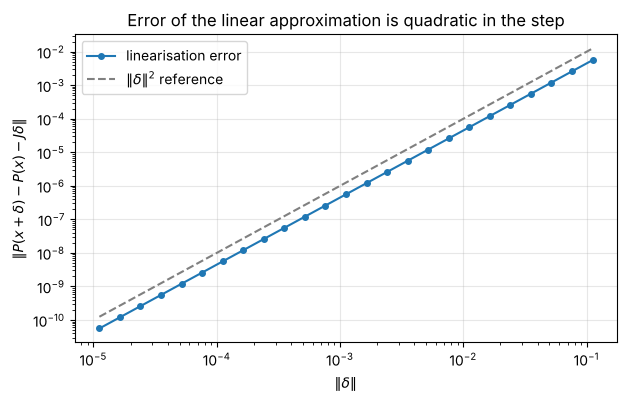

In [7]:
def polar(v):
    r, th = v
    return np.array([r * np.cos(th), r * np.sin(th)])

def jac_polar(v):
    r, th = v
    return np.array([[np.cos(th), -r * np.sin(th)],
                     [np.sin(th),  r * np.cos(th)]])

def jacobian_fd(F, x, h=1e-6):
    # numerical Jacobian: one central difference per input coordinate = one column each
    x = np.asarray(x, dtype=float)
    cols = []
    for i in range(x.size):
        e = np.zeros_like(x); e[i] = h
        cols.append((F(x + e) - F(x - e)) / (2 * h))
    return np.stack(cols, axis=1)

v0 = np.array([2.0, np.pi / 6])
print("analytic Jacobian:\n", jac_polar(v0))
print("numerical Jacobian:\n", jacobian_fd(polar, v0))
print("determinant:", np.linalg.det(jac_polar(v0)), " (should equal r = 2)")

# linearisation: predicted vs exact change for a perturbation delta, then shrink delta
delta = np.array([0.1, 0.05])
print("\nJ delta        :", jac_polar(v0) @ delta)
print("exact change   :", polar(v0 + delta) - polar(v0))

scales = np.logspace(-4, 0, 25)
lin_err = [np.linalg.norm(polar(v0 + s * delta) - polar(v0) - jac_polar(v0) @ (s * delta)) for s in scales]
plt.loglog(scales * np.linalg.norm(delta), lin_err, "o-", ms=4, label="linearisation error")
plt.loglog(scales * np.linalg.norm(delta), (scales * np.linalg.norm(delta))**2, "--", color="gray", label=r"$\|\delta\|^2$ reference")
plt.xlabel(r"$\|\delta\|$"); plt.ylabel(r"$\|P(x+\delta) - P(x) - J\delta\|$")
plt.title("Error of the linear approximation is quadratic in the step"); plt.legend(); plt.grid(alpha=0.3); plt.show()

In [8]:
# chain rule in matrix form: compose polar with a linear map g(p) = A p + c
A = np.array([[1.0, 2.0], [0.0, -1.0], [3.0, 1.0]])     # g: R^2 -> R^3
c = np.array([0.5, 0.0, -1.0])
g_lin = lambda p: A @ p + c
h_comp = lambda v: g_lin(polar(v))                      # h = g o P : R^2 -> R^3

J_chain = A @ jac_polar(v0)                             # J_g (constant A) times J_P
J_num = jacobian_fd(h_comp, v0)
print("J_g J_P (3x2):\n", J_chain)
print("max |chain rule - numerical| =", np.max(np.abs(J_chain - J_num)))

# backprop preview: a vector-Jacobian product never forms J explicitly
gbar = np.array([1.0, -2.0, 0.5])                       # dL/dh, say
print("VJP  J^T gbar          :", J_chain.T @ gbar)
print("same via two VJPs      :", jac_polar(v0).T @ (A.T @ gbar))

J_g J_P (3x2):
 [[ 1.86603  2.4641 ]
 [-0.5     -1.73205]
 [ 3.09808 -1.26795]]
max |chain rule - numerical| = 5.023914617652281e-10
VJP  J^T gbar          : [4.41506 5.29423]
same via two VJPs      : [4.41506 5.29423]


The analytic and numerical Jacobians agree to $10^{-9}$, and the linearisation error falls on
a line of slope 2 in the log-log plot — halve the step, quarter the error. The composed map's
Jacobian is the *product* $J_{\mathbf{g}}J_{\mathbf{P}}$ (shapes $3\times 2 = (3\times 2)(2\times 2)$),
and the backward pass of a network computes $J^\top\bar{\mathbf{g}}$ one factor at a time,
right to left, which is exactly what the last two lines show. Module 06 builds this machinery.

**Try it yourself:** evaluate `jac_polar` at `r = 0`. What happens to the determinant, and what does
that say about the inverse map (Cartesian to polar) at the origin?

## 5. The Hessian and second-order information

The Hessian $H_{ij} = \partial^2 f/\partial x_i\partial x_j$ is symmetric (Schwarz) and its
eigenvalues are the curvatures along its eigenvectors. At a critical point ($\nabla f = 0$):
all eigenvalues $> 0$ ⇒ minimum, all $< 0$ ⇒ maximum, mixed signs ⇒ saddle.

We use $f(x,y) = x^4 - 2x^2 + y^2$ (a "double well"): critical points are $(\pm 1, 0)$ and
$(0, 0)$, and we also look at $g(x,y) = -(x^2+y^2)$ and the guide's $x^2 + 3xy + 5y^2$.

In [9]:
def hessian_fd(f, x, h=1e-4):
    # numerical Hessian via second central differences (h larger than for first derivatives:
    # the round-off error now scales like eps/h^2)
    x = np.asarray(x, dtype=float); n = x.size
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            ei = np.zeros(n); ei[i] = h
            ej = np.zeros(n); ej[j] = h
            H[i, j] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * h * h)
    return H

def classify(H, tol=1e-8):
    lam = np.linalg.eigvalsh(H)
    if np.all(lam > tol):  return "local minimum", lam
    if np.all(lam < -tol): return "local maximum", lam
    if np.any(np.abs(lam) <= tol): return "degenerate (inconclusive)", lam
    return "saddle point", lam

dwell = lambda v: v[0]**4 - 2 * v[0]**2 + v[1]**2
hess_dwell = lambda v: np.array([[12 * v[0]**2 - 4, 0.0], [0.0, 2.0]])

for cp in [np.array([1.0, 0.0]), np.array([-1.0, 0.0]), np.array([0.0, 0.0])]:
    H_an, H_num = hess_dwell(cp), hessian_fd(dwell, cp)
    kind, lam = classify(H_an)
    print(f"critical point {cp}: gradient {grad_fd(dwell, cp).round(6)}, eigenvalues {lam}, -> {kind}"
          f"   (numerical Hessian error {np.max(np.abs(H_an - H_num)):.1e})")

print()
for name, H in {"x^2+3xy+5y^2": np.array([[2., 3.], [3., 10.]]),
                "x^2+3xy":      np.array([[2., 3.], [3., 0.]]),
                "-(x^2+y^2)":   np.array([[-2., 0.], [0., -2.]])}.items():
    kind, lam = classify(H)
    print(f"{name:14s} eigenvalues {lam.round(4)} -> {kind}")

critical point [1. 0.]: gradient [-0.  0.], eigenvalues [2. 8.], -> local minimum   (numerical Hessian error 8.2e-08)
critical point [-1.  0.]: gradient [0. 0.], eigenvalues [2. 8.], -> local minimum   (numerical Hessian error 7.9e-08)
critical point [0. 0.]: gradient [0. 0.], eigenvalues [-4.  2.], -> saddle point   (numerical Hessian error 8.0e-08)

x^2+3xy+5y^2   eigenvalues [ 1. 11.] -> local minimum
x^2+3xy        eigenvalues [-2.1623  4.1623] -> saddle point
-(x^2+y^2)     eigenvalues [-2. -2.] -> local maximum


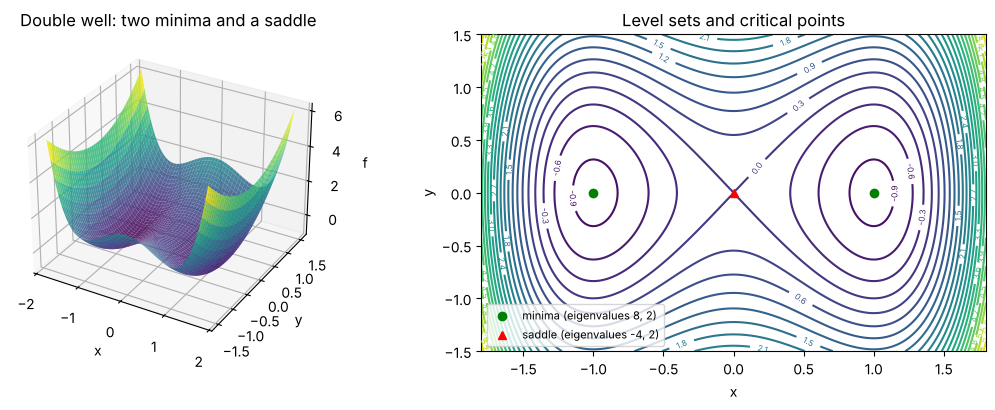

n = 1: fraction of random symmetric matrices that are positive definite = 0.4992   (coin-flip estimate 2^-n = 0.5000)
n = 2: fraction of random symmetric matrices that are positive definite = 0.1474   (coin-flip estimate 2^-n = 0.2500)
n = 3: fraction of random symmetric matrices that are positive definite = 0.0255   (coin-flip estimate 2^-n = 0.1250)
n = 4: fraction of random symmetric matrices that are positive definite = 0.0021   (coin-flip estimate 2^-n = 0.0625)
n = 6: fraction of random symmetric matrices that are positive definite = 0.0000   (coin-flip estimate 2^-n = 0.0156)
n = 8: fraction of random symmetric matrices that are positive definite = 0.0000   (coin-flip estimate 2^-n = 0.0039)


In [10]:
xs = np.linspace(-1.8, 1.8, 200); ys = np.linspace(-1.5, 1.5, 200)
X, Y = np.meshgrid(xs, ys)
Z = X**4 - 2 * X**2 + Y**2

fig = plt.figure(figsize=(11, 4.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.85, linewidth=0)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f"); ax.set_title("Double well: two minima and a saddle")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(X, Y, Z, levels=25, cmap="viridis"); ax2.clabel(cs, inline=True, fontsize=6, fmt="%.1f")
ax2.plot([1, -1], [0, 0], "go", label="minima (eigenvalues 8, 2)")
ax2.plot([0], [0], "r^", label="saddle (eigenvalues -4, 2)")
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_title("Level sets and critical points"); ax2.legend(fontsize=8)
fig.tight_layout(); plt.show()

# saddles dominate in high dimensions: random symmetric Hessians at "critical points"
trials = 20000
for n in (1, 2, 3, 4, 6, 8):
    M = rng.standard_normal((trials, n, n)); M = (M + np.swapaxes(M, 1, 2)) / 2
    lam = np.linalg.eigvalsh(M)
    frac_min = np.mean(np.all(lam > 0, axis=1))
    print(f"n = {n}: fraction of random symmetric matrices that are positive definite = {frac_min:.4f}"
          f"   (coin-flip estimate 2^-n = {2.0**-n:.4f})")

At $(\pm 1, 0)$ both eigenvalues are positive (bowl); at the origin the Hessian has
eigenvalues $-4$ and $2$ — curving down along $x$, up along $y$ — a saddle, which is why the
level sets there look like a cross. The last experiment shows how quickly "all curvatures
positive" becomes rare as dimension grows — for Gaussian random matrices even faster than the
coin-flip estimate $2^{-n}$, because eigenvalues of a random symmetric matrix repel each other
and spread symmetrically about zero. In a high-dimensional landscape, a point with zero gradient
is almost never a minimum. (A side note on `hessian_fd`: it uses `h = 1e-4`, much larger than for
first derivatives, because the second-difference formula divides by $h^2$ and its round-off term
is $\varepsilon/h^2$.)

## 6. Taylor expansion

$$f(a+h) = f(a) + f'(a)h + \frac{f''(a)}{2}h^2 + \dots + \frac{f^{(k)}(a)}{k!}h^k + O(h^{k+1}).$$

For $e^x$ about $0$ every derivative is $1$, so $T_k(x) = \sum_{j=0}^{k} x^j/j!$. We overlay the
polynomials on the function and then measure how the error scales with $|x|$.

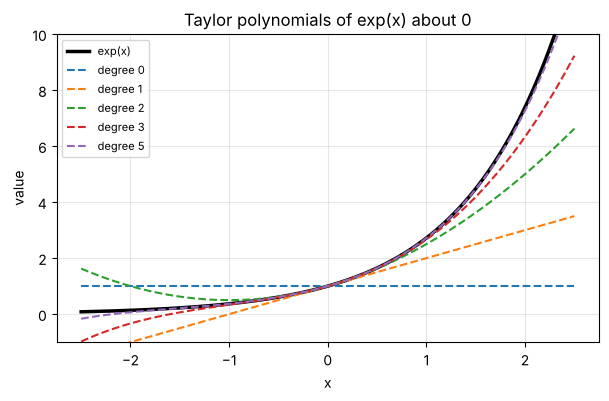

exp(0.5) = 1.6487212707001282
  degree 1: T_k = 1.500000, error = 1.49e-01
  degree 2: T_k = 1.625000, error = 2.37e-02
  degree 3: T_k = 1.645833, error = 2.89e-03
  degree 4: T_k = 1.648438, error = 2.84e-04


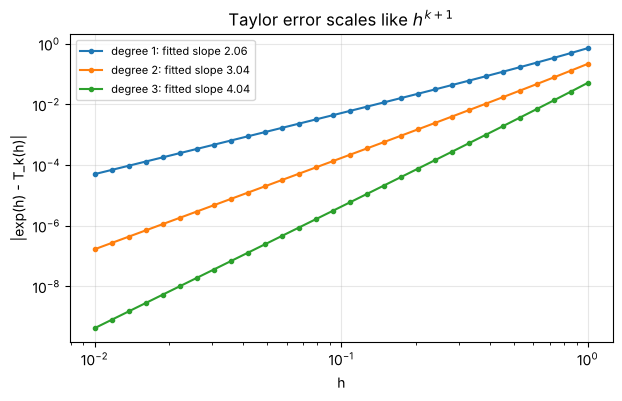

In [11]:
from math import factorial

def taylor_exp(x, k):
    return sum(x**j / factorial(j) for j in range(k + 1))

xs = np.linspace(-2.5, 2.5, 400)
plt.plot(xs, np.exp(xs), "k", lw=2.5, label="exp(x)")
for k in (0, 1, 2, 3, 5):
    plt.plot(xs, taylor_exp(xs, k), "--", label=f"degree {k}")
plt.ylim(-1, 10); plt.xlabel("x"); plt.ylabel("value"); plt.title("Taylor polynomials of exp(x) about 0")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

print("exp(0.5) =", np.exp(0.5))
for k in (1, 2, 3, 4):
    print(f"  degree {k}: T_k = {taylor_exp(0.5, k):.6f}, error = {np.exp(0.5) - taylor_exp(0.5, k):.2e}")

# error scaling: for degree k, error ~ C h^(k+1)
hs = np.logspace(-2, 0, 30)
for k in (1, 2, 3):
    err = np.abs(np.exp(hs) - taylor_exp(hs, k))
    slope = np.polyfit(np.log(hs), np.log(err), 1)[0]
    plt.loglog(hs, err, "o-", ms=3, label=f"degree {k}: fitted slope {slope:.2f}")
plt.xlabel("h"); plt.ylabel("|exp(h) - T_k(h)|"); plt.title("Taylor error scales like $h^{k+1}$")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

Each extra term buys roughly two more correct digits at $x = 0.5$, and the log-log slopes
come out as $2, 3, 4$ for degrees $1, 2, 3$ — the remainder is $O(h^{k+1})$ as promised.
The polynomials are excellent near $0$ and useless far away: a Taylor model is *local*.

The multivariate version, $f(\mathbf{x}+\boldsymbol{\delta}) \approx f + \nabla f^\top\boldsymbol{\delta} + \tfrac12\boldsymbol{\delta}^\top H\boldsymbol{\delta}$,
is the model gradient descent and Newton's method minimise. One consequence: on a quadratic
with Hessian eigenvalues $\lambda_i$, a gradient step multiplies the error along each
eigendirection by $(1 - \eta\lambda_i)$, so the method is stable only for $\eta < 2/\lambda_{\max}$.

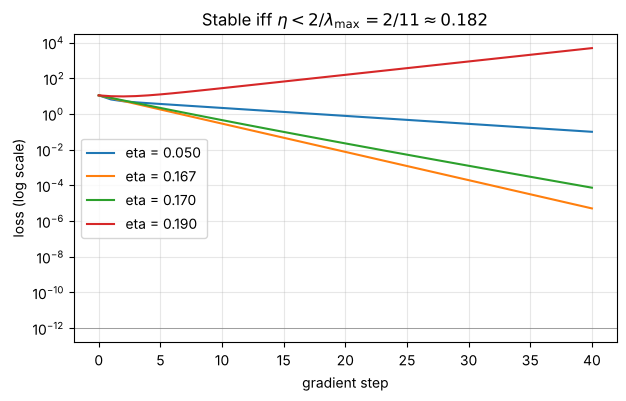

predicted contraction per step at eta = 1/6: 0.8333333333333334 (flat dir) and 0.8333333333333333 (sharp dir)


In [12]:
# gradient descent on the quadratic with Hessian [[2,3],[3,10]] (eigenvalues 1 and 11)
H = np.array([[2.0, 3.0], [3.0, 10.0]])
quad = lambda v: 0.5 * v @ H @ v
x_start = np.array([3.0, -2.0])

def run_gd(eta, steps=40):
    x = x_start.copy(); hist = [quad(x)]
    for _ in range(steps):
        x = x - eta * (H @ x)             # gradient of 0.5 x^T H x is H x (H symmetric)
        hist.append(quad(x))
    return np.array(hist)

for eta in (0.05, 1/6, 0.17, 0.19):
    hist = run_gd(eta)
    plt.semilogy(hist, label=f"eta = {eta:.3f}")
plt.axhline(1e-12, color="gray", lw=0.5)
plt.xlabel("gradient step"); plt.ylabel("loss (log scale)"); plt.title(r"Stable iff $\eta < 2/\lambda_{\max} = 2/11 \approx 0.182$")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print("predicted contraction per step at eta = 1/6:", 1 - (1/6) * 1, "(flat dir) and", abs(1 - (1/6) * 11), "(sharp dir)")

With $\eta = 0.19 > 2/11$ the loss explodes (the sharp direction is multiplied by $-1.09$ each
step); with $\eta = 1/6$ both directions contract by $5/6$ per step. The learning rate is
dictated by the *largest* curvature while progress along the *smallest* curvature is what
takes long — the conditioning story of Module 05.

**Try it yourself:** replace `H` by `[[1, 0], [0, 100]]` (condition number 100). How many steps
does the flat direction now need at the largest stable learning rate?

## 7. Matrix calculus identities, verified numerically

| expression | gradient |
|---|---|
| $\mathbf{a}^\top\mathbf{x}$ | $\mathbf{a}$ |
| $\mathbf{x}^\top A\mathbf{x}$ | $(A + A^\top)\mathbf{x}$ |
| $\lVert B\mathbf{x}-\mathbf{b}\rVert^2$ | $2B^\top(B\mathbf{x}-\mathbf{b})$ |
| $\operatorname{tr}(XA)$ | $A^\top$ |
| $\log\det X$ | $X^{-\top}$ |

Random matrices plus `grad_fd` from Section 3 give an independent check of each row. Note
that `A` below is deliberately *not* symmetric, so $2A\mathbf{x}$ would be wrong.

In [13]:
n, m = 4, 6
a = rng.standard_normal(n)
A = rng.standard_normal((n, n))                 # NOT symmetric on purpose
B = rng.standard_normal((m, n))
b = rng.standard_normal(m)
x = rng.standard_normal(n)

checks = {
    "grad a^T x = a":                     (grad_fd(lambda v: a @ v, x),                     a),
    "grad x^T A x = (A + A^T) x":         (grad_fd(lambda v: v @ A @ v, x),                 (A + A.T) @ x),
    "grad x^T A x != 2 A x (asym. A)":    (grad_fd(lambda v: v @ A @ v, x),                 2 * A @ x),
    "grad ||Bx - b||^2 = 2 B^T (Bx - b)": (grad_fd(lambda v: np.sum((B @ v - b)**2), x),    2 * B.T @ (B @ x - b)),
}
for name, (num, ana) in checks.items():
    print(f"{name:36s} max |numerical - formula| = {np.max(np.abs(num - ana)):.2e}")

# matrix-valued inputs: flatten X to use the same finite-difference helper
X = rng.standard_normal((3, 3)) + 4 * np.eye(3)          # well-conditioned, positive determinant
C = rng.standard_normal((3, 3))
g_tr = grad_fd(lambda v: np.trace(v.reshape(3, 3) @ C), X.ravel()).reshape(3, 3)
g_ld = grad_fd(lambda v: np.log(np.linalg.det(v.reshape(3, 3))), X.ravel()).reshape(3, 3)
print(f"{'grad tr(XC) = C^T':36s} max error = {np.max(np.abs(g_tr - C.T)):.2e}")
print(f"{'grad log det X = X^-T':36s} max error = {np.max(np.abs(g_ld - np.linalg.inv(X).T)):.2e}")

grad a^T x = a                       max |numerical - formula| = 3.35e-11
grad x^T A x = (A + A^T) x           max |numerical - formula| = 4.66e-10
grad x^T A x != 2 A x (asym. A)      max |numerical - formula| = 3.14e+00
grad ||Bx - b||^2 = 2 B^T (Bx - b)   max |numerical - formula| = 4.96e-09
grad tr(XC) = C^T                    max error = 1.01e-09
grad log det X = X^-T                max error = 1.89e-10


In [14]:
# least squares: gradient = 0  <=>  normal equations. The guide's 3-point line fit:
B3 = np.array([[1., 0.], [1., 1.], [1., 2.]]); b3 = np.array([1., 2., 2.])
loss = lambda v: np.sum((B3 @ v - b3)**2)
grad_ls = lambda v: 2 * B3.T @ (B3 @ v - b3)

x0 = np.array([0.0, 1.0])
print("loss at x0 =", loss(x0), "  gradient =", grad_ls(x0), "  numerical:", grad_fd(loss, x0))

x_star = np.linalg.solve(B3.T @ B3, B3.T @ b3)
print("normal-equation solution x* =", x_star, "  loss* =", loss(x_star))
print("gradient at x* =", grad_ls(x_star).round(12), "  (zero: first-order optimality)")
print("residual at x* =", (B3 @ x_star - b3).round(6), "  B^T residual =", (B3.T @ (B3 @ x_star - b3)).round(12))
print("np.linalg.lstsq agrees:", np.allclose(np.linalg.lstsq(B3, b3, rcond=None)[0], x_star))

loss at x0 = 2.0   gradient = [-4. -2.]   numerical: [-4. -2.]
normal-equation solution x* = [1.16667 0.5    ]   loss* = 0.16666666666666674
gradient at x* = [0. 0.]   (zero: first-order optimality)
residual at x* = [ 0.16667 -0.33333  0.16667]   B^T residual = [0. 0.]
np.linalg.lstsq agrees: True


Every identity matches finite differences to $10^{-9}$ or better, and the row labelled
`!= 2 A x` shows a large error — the $A^\top$ is not optional for a non-symmetric $A$. The
least-squares block is Module 02's normal equations rediscovered as "set the gradient to
zero": at $\mathbf{x}^*$ the residual is orthogonal to the columns of $B$ (that is what
$B^\top\mathbf{r}^* = \mathbf{0}$ says) and `np.linalg.lstsq` returns the same point.

## 8. Gradients of ML losses: logistic regression by hand

With $z_i = \mathbf{w}^\top\mathbf{x}_i$, $p_i = \sigma(z_i)$ and the binary cross-entropy
$L = -\frac1n\sum_i [y_i\ln p_i + (1-y_i)\ln(1-p_i)]$, the chain rule gives the famously
clean result

$$\frac{\partial L}{\partial z_i} = \frac{p_i - y_i}{n}, \qquad \nabla_{\mathbf{w}} L = \frac1n X^\top(\mathbf{p} - \mathbf{y}).$$

We check it on a synthetic dataset, take a few gradient steps and watch the loss fall and
the predictions become calibrated in aggregate.

In [15]:
# synthetic 2-feature dataset with an intercept column
n = 200
X_raw = rng.standard_normal((n, 2))
w_true = np.array([0.5, 2.0, -1.5])                     # intercept, w1, w2
X = np.column_stack([np.ones(n), X_raw])
p_true = sigmoid(X @ w_true)
y = (rng.random(n) < p_true).astype(float)

def bce_loss(w):
    z = X @ w
    # numerically stable: log(1+exp(-z)) = softplus(-z), and -log(1-p) = softplus(z)
    return np.mean(np.logaddexp(0, -z) * y + np.logaddexp(0, z) * (1 - y))

def bce_grad(w):
    p = sigmoid(X @ w)
    return X.T @ (p - y) / n

w0 = np.zeros(3)
print("analytic gradient :", bce_grad(w0))
print("numerical gradient:", grad_fd(bce_loss, w0))
print("relative error    :", np.linalg.norm(bce_grad(w0) - grad_fd(bce_loss, w0)) / np.linalg.norm(bce_grad(w0)))

analytic gradient : [-0.005   -0.24123  0.22477]
numerical gradient: [-0.005   -0.24123  0.22477]
relative error    : 2.9400396248759874e-10


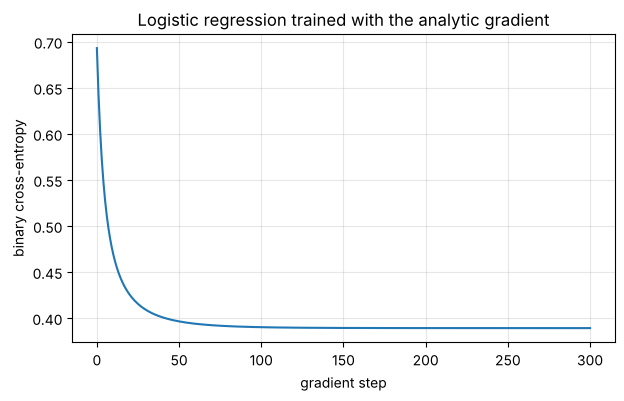

learned w        : [ 0.40437  2.15587 -1.6541 ]
true  w          : [ 0.5  2.  -1.5]
mean prediction  : 0.5049439498286181    positive rate: 0.505   (calibration in aggregate)
||gradient|| at end: 0.0002814125095748096
accuracy         : 0.805


In [16]:
w, eta = np.zeros(3), 0.5
hist = [bce_loss(w)]
for step in range(300):
    w = w - eta * bce_grad(w)
    hist.append(bce_loss(w))

plt.plot(hist); plt.xlabel("gradient step"); plt.ylabel("binary cross-entropy")
plt.title("Logistic regression trained with the analytic gradient"); plt.grid(alpha=0.3); plt.show()

p_hat = sigmoid(X @ w)
print("learned w        :", w)
print("true  w          :", w_true)
print("mean prediction  :", p_hat.mean(), "   positive rate:", y.mean(), "  (calibration in aggregate)")
print("||gradient|| at end:", np.linalg.norm(bce_grad(w)))
print("accuracy         :", np.mean((p_hat > 0.5) == (y == 1)))

The analytic gradient $X^\top(\mathbf{p}-\mathbf{y})/n$ matches finite differences to about
$10^{-10}$ in relative error, the loss decreases monotonically with a reasonable step size
(logistic loss is convex), and at the end the mean predicted probability equals the empirical
positive rate — the intercept component of "$\nabla L = 0$" reads $\sum_i p_i = \sum_i y_i$.
The learned weights sit near the true ones, with the discrepancy you would expect from 200 noisy
labels.

**Try it yourself:** set `eta = 5.0`. Does the convex loss still decrease at every step? Then
replace `bce_loss` by the squared error `np.mean((sigmoid(X @ w) - y)**2)` and its gradient
`X.T @ ((p - y) * p * (1 - p)) / n` — compare the speed of training and the final calibration.

## Summary

- A derivative is a sensitivity and the slope of the best linear approximation; a central
  difference estimates it with error $O(h^2)$ until round-off ($\varepsilon/h$) takes over around
  $h \approx 10^{-6}$ — the V-shaped error curve.
- The chain rule multiplies slopes; the activation derivatives $\sigma(1-\sigma)$,
  $1-\tanh^2$ and the ReLU mask are what backprop multiplies by, and $\sigma' \le 1/4$ is why
  deep sigmoid networks vanish.
- The gradient is the direction of steepest ascent (Cauchy–Schwarz) and is perpendicular to
  level sets; directional derivatives are $\nabla f^\top\mathbf{u}$.
- The Jacobian linearises a vector map; Jacobians of composed maps multiply; backprop
  computes $J^\top\bar{\mathbf{g}}$ one layer at a time.
- The Hessian's eigenvalues classify critical points; in high dimensions almost all critical
  points are saddles; $\eta < 2/\lambda_{\max}$ keeps gradient descent stable.
- Taylor models are local: the degree-$k$ error scales as $h^{k+1}$; gradient descent and
  Newton's method minimise first- and second-order Taylor models.
- $\nabla \mathbf{x}^\top A\mathbf{x} = (A+A^\top)\mathbf{x}$ and
  $\nabla\lVert B\mathbf{x}-\mathbf{b}\rVert^2 = 2B^\top(B\mathbf{x}-\mathbf{b})$; setting the latter
  to zero gives the normal equations.
- Logistic loss has gradient $X^\top(\mathbf{p}-\mathbf{y})/n$, which makes the fitted model
  calibrated in aggregate — and every one of these formulas was confirmed with finite differences.

**Next:** open `exercises.ipynb` and implement these ideas yourself, ending with a reusable
gradient checker.